In [1]:
# ── Cell 1: Install dependencies (pinned, compatible set) ──────────────────
import accelerate
!pip install -q \
    transformers==4.41.0 \
    accelerate==1.13.0 \
    datasets \
    scikit-learn \
    peft==0.11.0
# Ensure `accelerate` is imported before `transformers` for proper integration.
# Also check if a GPU is available and configure accelerate if needed.
# For example, by running `!accelerate config` in a separate cell if you need custom settings.
# For most cases, a simple import is enough for it to set up necessary hooks.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 81.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.2/251.2 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 73.4 MB/s eta 0:00:00


In [2]:
# ── Cell 1.5: Set up LoRA ──────────────────
from peft import LoraConfig, get_peft_model, TaskType

In [3]:
# ── Cell 2: Set up Kaggle credentials & download datasets ──────────────────
!pip install -q kaggle

from google.colab import files
print("Upload your kaggle.json below:")
files.upload()

import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

!kaggle datasets download -d jackksoncsie/spam-email-dataset
!kaggle datasets download -d mirzayasirabdullah07/subscription-renewal-and-cancellation-dataset
!kaggle datasets download -d ganiyuolalekan/spam-assassin-email-classification-dataset

!unzip -o spam-email-dataset.zip
!unzip -o subscription-renewal-and-cancellation-dataset.zip
!unzip -o spam-assassin-email-classification-dataset.zip

!ls *.csv

Upload your kaggle.json below:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/jackksoncsie/spam-email-dataset
License(s): GNU Lesser General Public License 3.0
100% 2.86M/2.86M [00:01<00:00, 2.14MB/s]

Dataset URL: https://www.kaggle.com/datasets/mirzayasirabdullah07/subscription-renewal-and-cancellation-dataset
License(s): apache-2.0
100% 2.82k/2.82k [00:00<00:00, 8.08MB/s]

Dataset URL: https://www.kaggle.com/datasets/ganiyuolalekan/spam-assassin-email-classification-dataset
License(s): Community Data License Agreement - Permissive - Version 1.0
100% 7.28M/7.28M [00:01<00:00, 4.05MB/s]

Archive:  spam-email-dataset.zip
  inflating: emails.csv              
Archive:  subscription-renewal-and-cancellation-dataset.zip
  inflating: subscription_dataset.csv  
Archive:  spam-assassin-email-classification-dataset.zip
  inflating: spam_assassin.csv       
emails.csv  spam_assassin.csv  subscription_dataset.csv


In [4]:
# ── Cell 3: Load & inspect raw data ───────────────────────────────────────
import pandas as pd

df_spam = pd.read_csv("emails.csv")
df_sub  = pd.read_csv("subscription_dataset.csv")

print("=== Spam dataset ===")
print(df_spam.shape)
print(df_spam.head(2))

print("\n=== Subscription dataset ===")
print(df_sub.shape)
print(df_sub.head(2))

=== Spam dataset ===
(5728, 2)
                                                text  spam
0  Subject: naturally irresistible your corporate...     1
1  Subject: the stock trading gunslinger  fanny i...     1

=== Subscription dataset ===
(120, 12)
  customer_id  age country subscription_type  monthly_fee  tenure_months  \
0    CUST0001   22    Oman          Standard        14.99             10   
1    CUST0002   67  Mexico           Premium         5.99             29   

   last_login_days  avg_monthly_usage_hours  support_tickets_last_6m  \
0               40                    34.66                        6   
1               51                    27.87                        3   

   auto_renew_enabled payment_method  cancelled  
0                   1         PayPal          1  
1                   0    Credit Card          0  


In [5]:
# ── Cell 4: Prepare spam dataframe ────────────────────────────────────────
df_spam = df_spam[['text', 'spam']].copy()
df_spam.columns = ['text', 'label']

# Use integer labels (required for SequenceClassification)
# 0 = NOT SPAM, 1 = SPAM, 2 = SUBSCRIPTION

df_spam['label'] = df_spam['label'].astype(int)

print(df_spam['label'].value_counts())
df_spam.head()

label
0    4360
1    1368
Name: count, dtype: int64


,text,label
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


In [6]:
# ── Cell 5: Prepare subscription dataframe ────────────────────────────────
import random

def convert_to_email(row):
    subjects = [
        f"Your {row['subscription_type']} subscription has been renewed",
        f"Subscription confirmation: {row['subscription_type']} plan",
        f"Receipt for your {row['subscription_type']} subscription",
        f"Billing update for your {row['subscription_type']} account",
    ]
    bodies = [
        (
            f"This is a confirmation that your {row['subscription_type']} subscription "
            f"has been successfully renewed.\n\n"
            f"Amount charged: ${row['monthly_fee']}\n"
            f"Payment method: {row['payment_method']}\n"
            f"Auto-renew: {'enabled' if row['auto_renew_enabled'] == 1 else 'disabled'}\n\n"
            f"To manage or cancel your subscription, visit your account settings."
        ),
        (
            f"Hi, we wanted to let you know your {row['subscription_type']} plan "
            f"has been renewed for ${row['monthly_fee']} this month.\n\n"
            f"If you did not authorize this charge or wish to cancel, "
            f"please contact support or visit account settings."
        ),
        (
            f"Your {row['subscription_type']} subscription is active.\n"
            f"Monthly fee: ${row['monthly_fee']} | Country: {row['country']}\n"
            f"Payment via {row['payment_method']}.\n\n"
            f"Thank you for staying with us."
        ),
    ]
    subject = random.choice(subjects)
    body = random.choice(bodies)
    return f"Subject: {subject}\n\n{body}"

random.seed(42)
df_sub = df_sub.copy()
df_sub['text']  = df_sub.apply(convert_to_email, axis=1)
df_sub['label'] = 2
df_sub = df_sub[['text', 'label']]

print(df_sub['label'].value_counts())
df_sub.head()

label
2    120
Name: count, dtype: int64


,text,label
0,Subject: Your Standard subscription has been r...,2
1,Subject: Receipt for your Premium subscription...,2
2,Subject: Subscription confirmation: Premium pl...,2
3,Subject: Your Basic subscription has been rene...,2
4,Subject: Your Basic subscription has been rene...,2


In [7]:
# ── Cell 6: Merge, shuffle, train/val split ────────────────────────────────
from sklearn.model_selection import train_test_split
import pandas as pd

# Load Spam Assassin ham emails as extra NOT SPAM data
df_assassin = pd.read_csv("spam_assassin.csv")  # check the actual filename from ls output
df_ham = df_assassin[df_assassin['target'] == 0][['text']].copy()
df_ham['label'] = 0  # 0 = NOT SPAM
df_ham = df_ham.sample(n=2000, random_state=42)  # take 2000 so it doesn't overwhelm

df = pd.concat([df_spam, df_sub, df_ham], ignore_index=True)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df = df.dropna(subset=['text'])

train_df, val_df = train_test_split(df, test_size=0.1, random_state=42, stratify=df['label'])

print(f"Train: {len(train_df)} | Val: {len(val_df)}")
print(df['label'].value_counts())

Train: 7063 | Val: 785
label
0    6360
1    1368
2     120
Name: count, dtype: int64


In [8]:
# ── Cell 6.5: check on cell 6 ─────────────────────────────────────────────────
print(df['label'].value_counts())

label
0    6360
1    1368
2     120
Name: count, dtype: int64


In [9]:
# ── Cell 7: Load tokenizer ─────────────────────────────────────────────────
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "right"

print("Tokenizer loaded:", MODEL_NAME)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer loaded: distilbert-base-uncased


In [10]:
# ── Cell 8: Tokenize datasets ─────────────────────────────────────────────
from datasets import Dataset

def tokenize(batch):
    return tokenizer(
        batch['text'],
        truncation=True,
        padding='max_length',
        max_length=256
    )

train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset   = Dataset.from_pandas(val_df.reset_index(drop=True))

train_dataset = train_dataset.map(tokenize, batched=True)
val_dataset   = val_dataset.map(tokenize, batched=True)

# DistilBERT needs 'labels' not 'label'
train_dataset = train_dataset.rename_column('label', 'labels')
val_dataset   = val_dataset.rename_column('label', 'labels')

train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
val_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

print(train_dataset)
print(train_dataset[0])

Map:   0%|          | 0/7063 [00:00<?, ? examples/s]

Map:   0%|          | 0/785 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'labels', 'input_ids', 'attention_mask'],
    num_rows: 7063
})
{'labels': tensor(1), 'input_ids': tensor([  101,  3395,  1024,  2191,  1037,  7280,  2006,  1041, 15907, 23380,
         2581,  2475,  1041, 15907,  1011,  1001,  1015,  6758,  2147,  2012,
         2188,  2449,  4495,  1011,  7473,  2932, 18023,  2024,  6719,  2108,
         2081,  1999,  2023,  2307,  2047, 18086,   999,  2058,  1002,  1023,
         4551,  1999, 16359,  2001,  2853,  2006,  1041, 15907,  1999,  2541,
         2011,  2111,  2074,  2066,  2017,  1011,  2157,  2013,  2037,  5014,
         1012,  2085,  2017,  2205,  2064,  4553,  1996,  7800,  1997,  3144,
         4855,  2006,  1041, 15907,  1998,  2191,  1037, 26233,  3318,  2013,
         1996,  7216,  1997,  2115,  2219,  2188,  1012,  2065,  2017,  2024,
        12774,  1010,  5214,  1997,  2383,  2019,  2330,  2568,  1010,  1998,
         2064,  3582,  3722,  7826,  1010,  2059,  3942,  2149,  2182,  1012,
         2

In [11]:
# ── Cell 9: Load model ─────────────────────────────────────────────────────
import torch
from transformers import AutoModelForSequenceClassification

id2label = {0: 'NOT SPAM', 1: 'SPAM', 2: 'SUBSCRIPTION'}
label2id = {v: k for k, v in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    target_modules=["q_lin", "v_lin"]
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
model = model.to(device)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 740,355 || all params: 67,696,134 || trainable%: 1.0936
Using device: cuda


In [12]:
# ── Cell 10: Training setup ────────────────────────────────────────────────
import numpy as np
import torch
from torch import nn
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score

# Compute class weights
class_counts = df['label'].value_counts().sort_index().values
weights = 1.0 / class_counts
weights = torch.tensor(weights / weights.sum(), dtype=torch.float).to(device)
print("Class weights:", weights)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=weights)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1': f1_score(labels, preds, average='weighted')
    }

training_args = TrainingArguments(
    output_dir='./spam_classifier',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=100,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=50,
    evaluation_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1',
    fp16=True,
    report_to='none'
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("Weighted Trainer ready!")

Class weights: tensor([0.0171, 0.0793, 0.9037], device='cuda:0')
Weighted Trainer ready!


/usr/local/lib/python3.12/dist-packages/transformers/training_args.py:1474: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


In [ ]:
# ── Cell 11: Train ─────────────────────────────────────────────────────────
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.088900,0.058671,0.978344,0.978690
2,0.034900,0.048623,0.983439,0.983416
3,0.034300,0.044085,0.985987,0.985967


/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


TrainOutput(global_step=1326, training_loss=0.18099933350248035, metrics={'train_runtime': 151.3072, 'train_samples_per_second': 140.04, 'train_steps_per_second': 8.764, 'total_flos': 1427546702066688.0, 'train_loss': 0.18099933350248035, 'epoch': 3.0})

In [ ]:
# ── Cell 12: Evaluate ──────────────────────────────────────────────────────
results = trainer.evaluate()
print(results)

{'eval_loss': 0.04408452659845352, 'eval_accuracy': 0.9859872611464968, 'eval_f1': 0.9859671006147808, 'eval_runtime': 2.367, 'eval_samples_per_second': 331.646, 'eval_steps_per_second': 10.562, 'epoch': 3.0}


              precision    recall  f1-score   support

    NOT SPAM       0.99      0.99      0.99       636
        SPAM       0.96      0.96      0.96       137
SUBSCRIPTION       1.00      1.00      1.00        12

    accuracy                           0.99       785
   macro avg       0.98      0.98      0.98       785
weighted avg       0.99      0.99      0.99       785



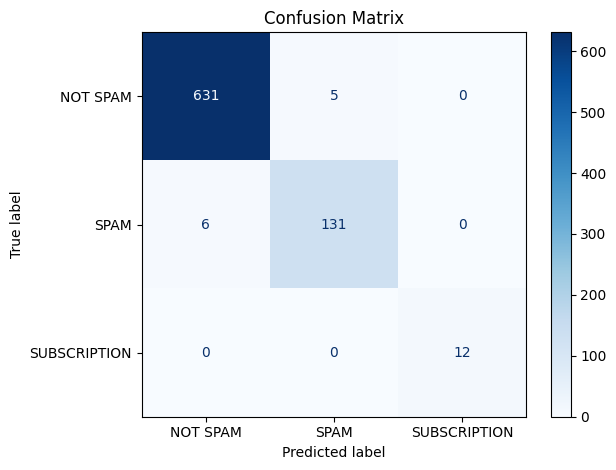

Confusion matrix saved as confusion_matrix.png


In [ ]:
# ── Cell 13: Confusion matrix & classification report ────────────────────
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Get predictions on the full validation set
predictions = trainer.predict(val_dataset)
preds = np.argmax(predictions.predictions, axis=-1)
labels = predictions.label_ids

label_names = ['NOT SPAM', 'SPAM', 'SUBSCRIPTION']

# Classification report
print(classification_report(labels, preds, target_names=label_names))

# Confusion matrix
cm = confusion_matrix(labels, preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()
print('Confusion matrix saved as confusion_matrix.png')

In [ ]:
# ── Cell 14: Save model & tokenizer ──────────────────────────────────────
import os

SAVE_PATH = './spam_classifier_final'
os.makedirs(SAVE_PATH, exist_ok=True)

model.save_pretrained(SAVE_PATH)

model.base_model.save_pretrained(os.path.join(SAVE_PATH, "base_model"))

tokenizer.save_pretrained(SAVE_PATH)
print(f'Model and tokenizer saved to {SAVE_PATH}')
print('Files saved:')
for f in os.listdir(SAVE_PATH):
    print(f'  - {f}')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Model and tokenizer saved to ./spam_classifier_final
Files saved:
  - base_model
  - tokenizer.json
  - vocab.txt
  - adapter_model.safetensors
  - special_tokens_map.json
  - README.md
  - adapter_config.json
  - tokenizer_config.json


In [ ]:
# ── Cell 15: Merge LoRA & save final model ──────────────────────────────────
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import torch

MERGED_PATH = './spam_classifier_merged'

model = model.merge_and_unload()

model.save_pretrained(MERGED_PATH)
tokenizer.save_pretrained(MERGED_PATH)

print(f'Merged model saved to {MERGED_PATH}')
print('Files saved:')
for f in os.listdir(MERGED_PATH):
    print(f'  - {f}')

model = AutoModelForSequenceClassification.from_pretrained(MERGED_PATH)
tokenizer = AutoTokenizer.from_pretrained(MERGED_PATH)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
model.eval()

print('Model reloaded successfully — no LoRA, no warnings!')

Merged model saved to ./spam_classifier_merged
Files saved:
  - tokenizer.json
  - vocab.txt
  - special_tokens_map.json
  - config.json
  - model.safetensors
  - tokenizer_config.json
Model reloaded successfully — no LoRA, no warnings!


In [ ]:
# ── Cell 16: Flask API server ─────────────────────────────────────────────
!pip install -q flask pyngrok

from flask import Flask, request, jsonify
from pyngrok import ngrok
import threading
import torch

app = Flask(__name__)

# ── predict function ───
def predict(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=256).to(device)

    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=1)

    pred_id = probs.argmax().item()
    confidence = probs[0][pred_id].item() * 100
    label = model.config.id2label[pred_id]

    text_lower = text.lower()
    subscription_keywords = [
        "subscription", "renewed", "billing", "charged",
        "plan", "membership", "auto-renew", "invoice"
    ]

    if any(word in text_lower for word in subscription_keywords):
        label = "SUBSCRIPTION"

    if label == "SPAM":
        spam_keywords = ["free", "win", "click", "urgent", "money", "offer"]
        found = [w for w in spam_keywords if w in text_lower]
        reason = f"Contains suspicious keywords: {', '.join(found)}" if found else "Spam-like pattern detected"
    elif label == "SUBSCRIPTION":
        reason = "Detected subscription-related terms (billing/renewal)"
    else:
        reason = "No strong spam indicators detected"

    if confidence > 70:
        level = "High"
    elif confidence > 50:
        level = "Medium"
    else:
        level = "Low"

    return {
        "label": label,
        "confidence": round(confidence, 2),
        "confidence_level": level,
        "reason": reason
    }

# ── Flask routes ───
@app.route('/predict', methods=['POST'])
def predict_api():
    data = request.json
    if not data or 'text' not in data:
        return jsonify({'error': 'No text provided'}), 400
    result = predict(data['text'])
    return jsonify(result)

@app.route('/health', methods=['GET'])
def health():
    return jsonify({'status': 'ok'})

# ── Start server ───
ngrok.set_auth_token("3CS8QTpx3jv3Mu67lg4HlGcrXQl_4fy24jsPeCmh9mpygLZca")

public_url = ngrok.connect(5000)
print(f'==============================================')
print(f'Public API URL : {public_url}')
print(f'Predict endpoint: {public_url}/predict')
print(f'Health check  : {public_url}/health')
print(f'Method        : POST')
print(f'Body example  : {{"text": "email content here"}}')
print(f'==============================================')

threading.Thread(target=lambda: app.run(port=5000)).start()


Public API URL : NgrokTunnel: "https://freeway-direction-shallow.ngrok-free.dev" -> "http://localhost:5000"
Predict endpoint: NgrokTunnel: "https://freeway-direction-shallow.ngrok-free.dev" -> "http://localhost:5000"/predict
Health check  : NgrokTunnel: "https://freeway-direction-shallow.ngrok-free.dev" -> "http://localhost:5000"/health
Method        : POST
Body example  : {"text": "email content here"}


In [ ]:
# ── Cell 17: Quick inference test ──────────────────────────────────────────
import torch

def predict(text):
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=256).to(device)

    with torch.no_grad():
        logits = model(**inputs).logits
        probs = torch.softmax(logits, dim=1)

    pred_id = probs.argmax().item()
    confidence = probs[0][pred_id].item() * 100

    label = model.config.id2label[pred_id]

    text_lower = text.lower()
    subscription_keywords = [
        "subscription", "renewed", "billing", "charged",
        "plan", "membership", "auto-renew", "invoice"
    ]

    if any(word in text_lower for word in subscription_keywords):
        label = "SUBSCRIPTION"

    if label == "SPAM":
        spam_keywords = ["free", "win", "click", "urgent", "money", "offer"]
        found = [w for w in spam_keywords if w in text_lower]
        reason = f"Contains suspicious keywords: {', '.join(found)}" if found else "Spam-like pattern detected"

    elif label == "SUBSCRIPTION":
        reason = "Detected subscription-related terms (billing/renewal)"

    else:
        reason = "No strong spam indicators detected"

    if confidence > 70:
        level = "High"
    elif confidence > 50:
        level = "Medium"
    else:
        level = "Low"

    message = None
    if label == "SUBSCRIPTION":
        message = "Go to account settings → billing → cancel subscription"

    print("\n" + "=" * 55)
    print("Email Analysis Result")
    print("=" * 55)
    print(f"Category     : {label}")
    print(f"Confidence   : {level} ({confidence:.0f}%)")
    print(f"Reason       : {reason}")
    print("=" * 55)

    if label == "SUBSCRIPTION":
        print("How to cancel your subscription:")
        print("  1. Log in to your account")
        print("  2. Go to Settings > Billing")
        print("  3. Click 'Cancel Subscription'")
        print("  4. Confirm cancellation")
        print("  5. Check confirmation email")
        print("=" * 55)

    return {
        "label": label,
        "confidence": round(confidence, 2),
        "reason": reason,
        "message": message
    }

tests = [
    "Free money!!! Click now!!! You've been selected!",
    "Your monthly subscription to Netflix has been renewed for $15.99.",
    "Hi, here are the meeting notes from yesterday's standup.",
]

for t in tests:
    predict(t)
    print()

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit



Email Analysis Result
Category     : SPAM
Confidence   : High (100%)
Reason       : Contains suspicious keywords: free, click, money


Email Analysis Result
Category     : SUBSCRIPTION
Confidence   : High (72%)
Reason       : Detected subscription-related terms (billing/renewal)
How to cancel your subscription:
  1. Log in to your account
  2. Go to Settings > Billing
  3. Click 'Cancel Subscription'
  4. Confirm cancellation
  5. Check confirmation email


Email Analysis Result
Category     : NOT SPAM
Confidence   : High (99%)
Reason       : No strong spam indicators detected



In [ ]:
# ── Cell 18: Zip file download (you don't have to run this cell) ──────────────────────────────────────────
from google.colab import files
import shutil

shutil.make_archive('spam_model', 'zip', './spam_classifier_merged')
files.download('spam_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>